# Neural LM + Grammar Anchors + Cardinality Constraints
## Decipherment of the Voynich Manuscript with LSTM and Controllable Temperature

The paper identifies **LM dominance** as the root cause of degenerate mapping: the trigram LM with Witten-Bell smoothing forces collapse of 166 glyphs into a few high-frequency Hebrew characters.

This notebook implements:
1. **Neural CharLM** (LSTM) with adjustable temperature T
2. **Grammar anchors** (glyphs with fixed roles)
3. **Cardinality constraints** (K_max)
4. **Hebrew only** — the most promising language

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cuda
Imports OK


In [2]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# ── Segmentation and positional classification ──

def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ── Load and process Voynich ──
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')
print(f'Classification: C={n_c}, V={n_v}, ?={n_q}')

Voynich: 37,087 palabras, 157,254 tokens, 166 glifos
Clasificación: C=70, V=5, ?=91


In [3]:
# ── Cell 3: Load Hebrew corpus + CharLM baseline + grammar anchors ──

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_words):,} words')
    return todas_palabras

print('Downloading Hebrew corpus (Torah)...')
hebrew_words_full = descargar_hebreo()

# Subsample
rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Hebrew subsampled: {len(hebrew_words):,} words')

# Hebrew C/V classification
HEBREW_VOWELS = set('אהוי')  # matres lectionis
target_chars_heb = sorted(set(c for w in hebrew_words for c in w))
char_role_heb = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars_heb}
n_c_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_v_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Hebrew: {len(target_chars_heb)} chars (C={n_c_h}, V={n_v_h})')

# ── Trigram CharLM baseline (Witten-Bell) ──
class CharLM:
    """Character-level trigram LM with Witten-Bell smoothing."""
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS, EOS = '<w>', '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS, EOS = '<w>', '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp, total_n = 0.0, 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)

# Train baseline
char_lm_baseline = CharLM(order=3)
char_lm_baseline.fit(hebrew_words)
ppx_baseline = char_lm_baseline.perplexity(hebrew_words)
print(f'CharLM baseline native PPX: {ppx_baseline:.2f}')

# ── Grammar anchors ──
HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets

glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

role_counts = Counter(glyph_grammar_role.values())
print(f'\nGrammar anchors: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt}')

Descargando corpus hebreo (Torah)...
  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 palabras
Hebreo subsampleado: 37,087 palabras
Hebreo: 27 chars (C=23, V=4)
CharLM baseline PPX nativa: 7.32

Grammar anchors: 12 glifos
  root: 7
  suffix: 2
  prefix: 2
  classifier: 1


In [4]:
# ── Cell 4: NeuralCharLM — LSTM architecture ─────────────────────────

class CharDataset(Dataset):
    """Dataset of words as sequences of character indices."""
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]  # bigram context (2 chars)
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    """Character-level LSTM language model with controllable temperature."""

    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers

        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

        # Store char mappings (set after creation)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        """x: (batch, seq_len) -> logits: (batch, seq_len, vocab_size)"""
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        """Log2-probability of a single word (list of chars) with temperature.
        Uses independent bigram contexts (matches training setup).
        For batch processing, use batch_log_prob() instead.
        """
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]

            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)

            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        """Batched log2-probability for multiple words on GPU.

        Collects all bigram contexts across all words into a single batch,
        runs one forward pass, and distributes results back per word.
        ~100-1000x faster than calling log_prob() in a loop.
        """
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)

        with torch.no_grad():
            # Collect all bigram contexts and targets
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]  # cumulative count of bigrams per word

            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))

            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))

            ctx_t = torch.tensor(all_ctx, device=DEVICE)   # (N, 2)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)   # (N,)

            # Process in GPU-friendly chunks
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])      # (chunk, 2, vocab)
                logits_last = logits[:, -1, :] / temperature    # (chunk, vocab)
                log_p = torch.log_softmax(logits_last, dim=-1)  # (chunk, vocab)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)

            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)  # log2

            # Sum per word
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()

            return word_lps

    def perplexity(self, words, temperature=1.0):
        """Perplexity over a corpus of words (uses batched scoring)."""
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)  # +1 for EOS
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Build vocabulary and indices ──
all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} chars + {len(special_tokens)} special)')
print(f'Architecture: embed={32}, hidden={192}, layers={2}, dropout={0.2}')
n_params = sum(p.numel() for p in NeuralCharLM(len(char_vocab)).parameters())
print(f'Parameters: {n_params:,}')

Neural LM vocab: 31 tokens (27 chars + 4 special)
Arquitectura: embed=32, hidden=192, layers=2, dropout=0.2
Parámetros: 476,991


Train: 29,670 words, Val: 7,417 words
Train samples: 142,813, Val samples: 35,563

Entrenando Neural LM (30 epochs, patience=5)...
  Epoch  1: train_loss=2.3432, val_loss=2.1494, lr=0.001995
  Epoch  5: train_loss=2.0585, val_loss=2.0304, lr=0.001866
  Epoch 10: train_loss=2.0327, val_loss=2.0160, lr=0.001500
  Epoch 15: train_loss=2.0207, val_loss=2.0099, lr=0.001000
  Epoch 20: train_loss=2.0111, val_loss=2.0064, lr=0.000500
  Epoch 25: train_loss=2.0034, val_loss=2.0042, lr=0.000134
  Epoch 30: train_loss=2.0004, val_loss=2.0037, lr=0.000000

Entrenamiento completado en 47.9s

Perplexity en validación (2000 words):
  CharLM trigram (baseline): 7.37
  NeuralCharLM (T=1.0):     7.48
  Ratio neural/baseline:     1.015


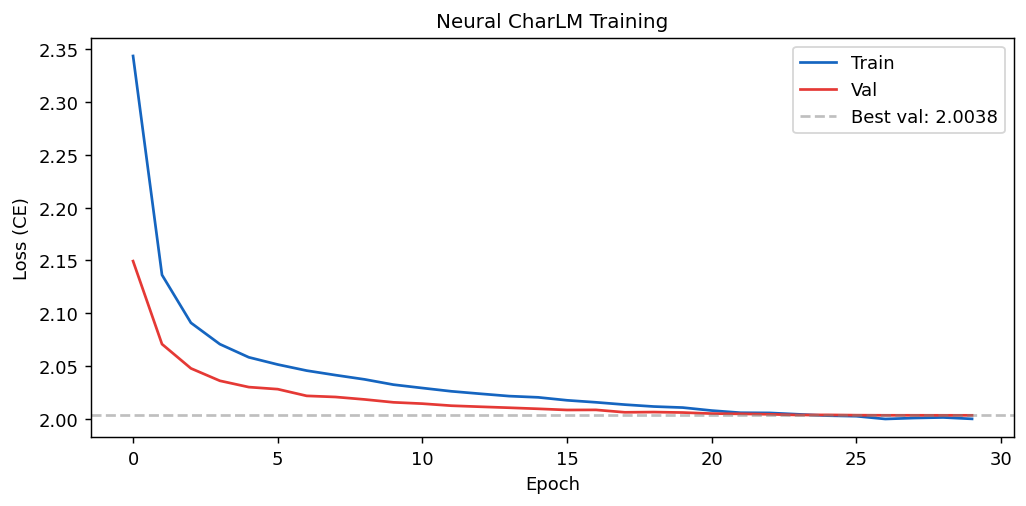

In [5]:
# ── Cell 5: Neural LM training ──────────────────────────────

# Train/val split
rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]
print(f'Train: {len(train_words):,} words, Val: {len(val_words):,} words')

# Datasets
train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f'Train samples: {len(train_dataset):,}, Val samples: {len(val_dataset):,}')

# Model
neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

# Training setup
optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

# Training loop
N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses = []
val_losses = []

print(f'\nTraining Neural LM ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    # Train
    neural_lm.train()
    epoch_loss = 0.0
    n_batches = 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        # logits shape: (batch, 2, vocab) — we want prediction at last position
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    # Validate
    neural_lm.eval()
    val_loss = 0.0
    n_val_batches = 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)

    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'lr={scheduler.get_last_lr()[0]:.6f}')

    # Early stopping
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining completed in {elapsed:.1f}s')

# Restore best
neural_lm.load_state_dict(best_state_dict)

# Compare perplexities
neural_val_ppx = neural_lm.perplexity(val_words[:2000], temperature=1.0)
baseline_val_ppx = char_lm_baseline.perplexity(val_words[:2000])
print(f'\nPerplexity on validation (2000 words):')
print(f'  CharLM trigram (baseline): {baseline_val_ppx:.2f}')
print(f'  NeuralCharLM (T=1.0):     {neural_val_ppx:.2f}')
print(f'  Ratio neural/baseline:     {neural_val_ppx/baseline_val_ppx:.3f}')

# Plot training curves
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, linestyle='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CE)')
ax.set_title('Neural CharLM Training')
ax.legend()
plt.tight_layout()
plt.show()

Sweep de temperatura: entropía promedio de P_T...


Temperature sweep:   0%|          | 0/8 [00:00<?, ?it/s]

  T=0.3: H_mean=1.184 bits, PPX=30.06
  T=0.5: H_mean=1.875 bits, PPX=11.46
  T=0.8: H_mean=2.624 bits, PPX=8.05
  T=1.0: H_mean=2.983 bits, PPX=7.72
  T=1.5: H_mean=3.577 bits, PPX=8.23
  T=2.0: H_mean=3.924 bits, PPX=9.23
  T=3.0: H_mean=4.313 bits, PPX=11.37
  T=5.0: H_mean=4.635 bits, PPX=14.98

Referencias:
  H_uniform (log2(27)): 4.755 bits


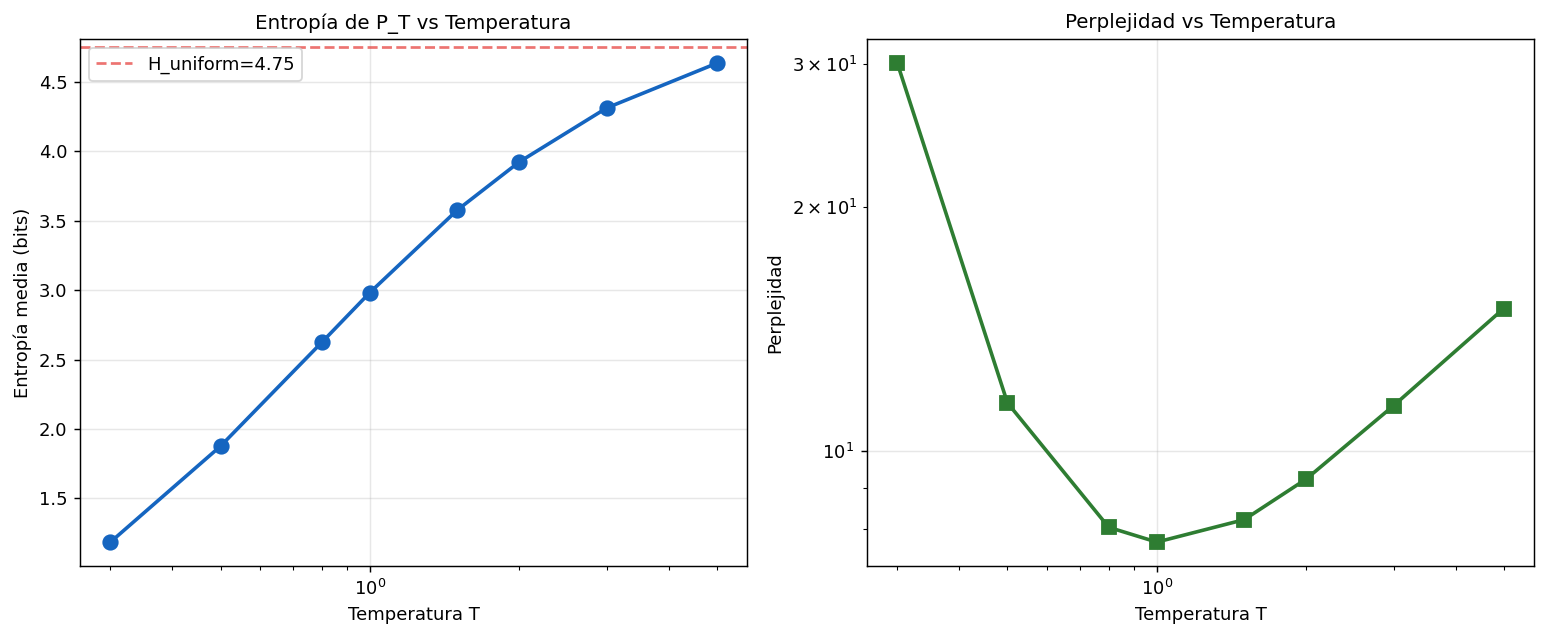


Resumen temperatura:
  T   H_mean       PPX
0.3 1.183957 30.062947
0.5 1.875401 11.460788
0.8 2.623804  8.047820
1.0 2.982885  7.716963
1.5 3.577144  8.225192
2.0 3.924065  9.230425
3.0 4.313081 11.370069
5.0 4.635107 14.979975


In [6]:
# ── Cell 6: Temperature analysis ──────────────────────────────────

TEMPERATURES = [0.3, 0.5, 0.8, 1.0, 1.5, 2.0, 3.0, 5.0]

# For each T: compute average entropy of the output distribution
print('Temperature sweep: average entropy of P_T...')
sample_words = val_words[:500]

temp_results = []
neural_lm.eval()

for T in tqdm(TEMPERATURES, desc='Temperature sweep'):
    entropies = []
    ppx_vals = []

    with torch.no_grad():
        for word in sample_words:
            bos = char2idx['<w>']
            eos = char2idx['</w>']
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0))
                                     for c in word] + [eos]
            h = None
            word_entropy = 0.0
            n_steps = 0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, h = neural_lm(ctx, h)
                logits_t = logits[0, -1, :] / T
                probs = torch.softmax(logits_t, dim=0).cpu().numpy()
                probs = probs[probs > 1e-12]
                H = -np.sum(probs * np.log2(probs))
                word_entropy += H
                n_steps += 1
            if n_steps > 0:
                entropies.append(word_entropy / n_steps)

    ppx = neural_lm.perplexity(sample_words[:200], temperature=T)
    H_mean = np.mean(entropies)
    temp_results.append({
        'T': T, 'H_mean': H_mean, 'PPX': ppx,
    })
    print(f'  T={T:.1f}: H_mean={H_mean:.3f} bits, PPX={ppx:.2f}')

# Reference entropies
H_uniform = np.log2(len(target_chars_heb))
H_baseline = -np.mean([
    sum(p * np.log2(p) for p in [v/sum(char_lm_baseline.unigram_counts.values())
        for v in char_lm_baseline.unigram_counts.values()] if p > 0)
])

print(f'\nReferences:')
print(f'  H_uniform (log2({len(target_chars_heb)})): {H_uniform:.3f} bits')

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

Ts = [r['T'] for r in temp_results]
Hs = [r['H_mean'] for r in temp_results]
PPXs = [r['PPX'] for r in temp_results]

ax1.plot(Ts, Hs, 'o-', color='#1565C0', linewidth=2, markersize=8)
ax1.axhline(H_uniform, linestyle='--', color='#E53935', alpha=0.7, label=f'H_uniform={H_uniform:.2f}')
ax1.set_xlabel('Temperature T')
ax1.set_ylabel('Mean entropy (bits)')
ax1.set_title('Entropy of P_T vs Temperature')
ax1.set_xscale('log')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(Ts, PPXs, 's-', color='#2E7D32', linewidth=2, markersize=8)
ax2.set_xlabel('Temperature T')
ax2.set_ylabel('Perplexity')
ax2.set_title('Perplexity vs Temperature')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary table
df_temp = pd.DataFrame(temp_results)
print('\nTemperature summary:')
print(df_temp.to_string(index=False))

In [7]:
# ── Cell 7: GlyphMappingState + Scoring neural (batched) ─────────────

class GlyphMappingState:
    """Mapping of Voynich glyphs to Hebrew characters (many-to-one)."""

    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def propose_change_tracked(self, rng, constrained=True):
        """Like propose_change but returns (new_state, changed_glyph)."""
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    """Frequency-based initialization within each C/V class."""
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def build_glyph_word_index(words):
    """Pre-build glyph → list of word indices for incremental scoring."""
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


# ── Scoring functions (batched) ──

def score_positional(mapping, glyph_role, char_role):
    """C/V consistency score."""
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_grammar(mapping_state, glyph_anchor_sets):
    """Grammar anchor compatibility: +1 if maps to anchor set, -1 if not."""
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        if mapping_state.mapping.get(g) in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy(mapping_state):
    """Normalized entropy of char usage distribution."""
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    """Neural LM score using batched GPU inference. Returns (mean_lp, per_word_lps)."""
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    """Penalty for low cardinality (few chars used)."""
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_total_neural(mapping_state, words_sample, neural_lm, temperature,
                       glyph_role, char_role, glyph_anchor_sets,
                       w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                       w_gram=1.0, K_max=23):
    """Total score with 5 components (batched LM). Returns (total, per_word_lps)."""
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_pos = score_positional(mapping_state, glyph_role, char_role)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    s_gram = score_grammar(mapping_state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm,
                            temperature, glyph_role, char_role, glyph_anchor_sets,
                            glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                            w_gram=1.0, K_max=23):
    """Incremental scoring: only re-score words affected by changed_glyph.
    Returns (total_score, updated_word_lps).
    """
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]

    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional(proposal, glyph_role, char_role)
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    s_gram = score_grammar(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps


print('Scoring functions loaded (batched + incremental):')
print('  score_total_neural, score_total_incremental')

Scoring functions loaded (batched + incremental):
  score_total_neural, score_total_incremental


Total configuraciones: 90
EM corto: 200 iter, patience=20, 500 words, incremental scoring
  [10/90] T=0.8, w_gram=1.0, K_max=20 -> score=-41.739, K=27, gram=0.50 [54s]
  [20/90] T=1.0, w_gram=0.5, K_max=23 -> score=-41.430, K=27, gram=0.50 [127s]
  [30/90] T=1.0, w_gram=1.0, K_max=27 -> score=-41.180, K=27, gram=0.50 [204s]
  [40/90] T=1.5, w_gram=0.5, K_max=20 -> score=-39.343, K=27, gram=0.83 [267s]
  [50/90] T=1.5, w_gram=2.0, K_max=23 -> score=-37.944, K=27, gram=1.00 [310s]
  [60/90] T=2.0, w_gram=0.5, K_max=27 -> score=-38.849, K=27, gram=0.67 [364s]
  [70/90] T=2.0, w_gram=2.0, K_max=20 -> score=-36.633, K=27, gram=1.00 [432s]
  [80/90] T=3.0, w_gram=1.0, K_max=23 -> score=-37.416, K=27, gram=1.00 [491s]
  [90/90] T=3.0, w_gram=2.0, K_max=27 -> score=-36.416, K=27, gram=1.00 [554s]

Sweep completado en 554s (9.2 min)

── Top 10 configuraciones ──
 Rank   T  w_gram  w_card  K_max   Score  K_eff Grammar  Iter
    1 3.0     2.0     0.5     20 -36.416     27    1.00   163
    2 3.0 

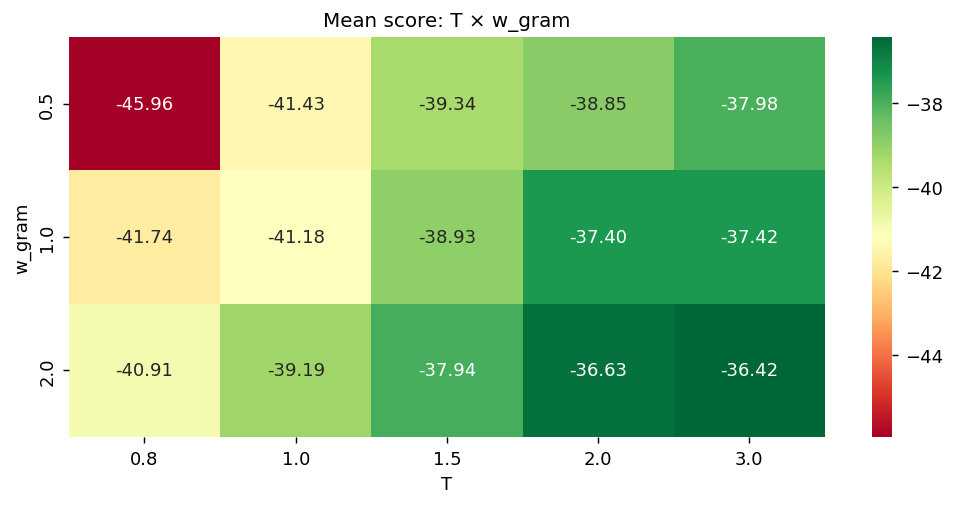


Top-3 seleccionados para EM completo:
  #1: T=3.0, w_gram=2.0, w_card=0.5, K_max=20, score=-36.416
  #2: T=3.0, w_gram=2.0, w_card=0.5, K_max=23, score=-36.416
  #3: T=3.0, w_gram=2.0, w_card=0.5, K_max=27, score=-36.416


In [8]:
# ── Cell 8: Hyperparameter sweep (temperature × weights) ───────────

# Subsample for fast scoring (500 words for sweep)
rng_sweep = np.random.default_rng(42)
SAMPLE_SIZE_SWEEP = 500
if len(palabras) > SAMPLE_SIZE_SWEEP:
    idx_sw = rng_sweep.choice(len(palabras), size=SAMPLE_SIZE_SWEEP, replace=False)
    words_sweep = [palabras[i] for i in idx_sw]
else:
    words_sweep = palabras

# Pre-build glyph → word index for incremental scoring
glyph_word_idx_sweep = build_glyph_word_index(words_sweep)

# Grid
T_VALUES = [0.8, 1.0, 1.5, 2.0, 3.0]
W_GRAM_VALUES = [0.5, 1.0, 2.0]
W_CARD_VALUES = [0.5, 1.0]
K_MAX_VALUES = [20, 23, 27]

configs = []
for T in T_VALUES:
    for w_gram in W_GRAM_VALUES:
        for w_card in W_CARD_VALUES:
            for K_max in K_MAX_VALUES:
                configs.append({'T': T, 'w_gram': w_gram, 'w_card': w_card, 'K_max': K_max})

print(f'Total configurations: {len(configs)}')
print(f'Short EM: 200 iter, patience=20, {SAMPLE_SIZE_SWEEP} words, incremental scoring')

# Base initialization
init_map = init_frequency_mapping(palabras, VOCAB, target_chars_heb, hebrew_words,
                                   glyph_role, char_role_heb)

sweep_results = []
t0_sweep = time.time()

for ci, cfg in enumerate(configs):
    T, w_gram, w_card, K_max = cfg['T'], cfg['w_gram'], cfg['w_card'], cfg['K_max']

    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(init_map)

    score_kw = dict(w_gram=w_gram, w_card=w_card, K_max=K_max)
    rng_em = np.random.default_rng(42)

    # Initial full scoring (batched)
    best_score, best_word_lps = score_total_neural(
        state, words_sweep, neural_lm, T,
        glyph_role, char_role_heb, glyph_anchor_sets, **score_kw)
    best_state = state
    no_improve = 0

    for it in range(200):
        improved = False
        for _ in range(100):
            proposal, changed_glyph = best_state.propose_change_tracked(rng_em, constrained=True)
            prop_score, prop_word_lps = score_total_incremental(
                proposal, changed_glyph, words_sweep, neural_lm, T,
                glyph_role, char_role_heb, glyph_anchor_sets,
                glyph_word_idx_sweep, best_word_lps, **score_kw)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                best_word_lps = prop_word_lps
                improved = True
        if not improved:
            no_improve += 1
            if no_improve >= 20:
                break
        else:
            no_improve = 0

    K_eff = len(set(best_state.mapping.values()))
    s_gram = score_grammar(best_state, glyph_anchor_sets)

    sweep_results.append({
        'T': T, 'w_gram': w_gram, 'w_card': w_card, 'K_max': K_max,
        'score': best_score, 'K_eff': K_eff, 'grammar': s_gram,
        'state': best_state,
        'iter_converged': it + 1,
    })

    if (ci + 1) % 10 == 0:
        elapsed = time.time() - t0_sweep
        print(f'  [{ci+1}/{len(configs)}] T={T}, w_gram={w_gram}, K_max={K_max} -> '
              f'score={best_score:.3f}, K={K_eff}, gram={s_gram:.2f} [{elapsed:.0f}s]')

elapsed_total = time.time() - t0_sweep
print(f'\nSweep completed in {elapsed_total:.0f}s ({elapsed_total/60:.1f} min)')

# Ranking
sweep_results.sort(key=lambda r: r['score'], reverse=True)

print('\n── Top 10 configurations ──')
rows_top = []
for i, r in enumerate(sweep_results[:10]):
    rows_top.append({
        'Rank': i+1, 'T': r['T'], 'w_gram': r['w_gram'], 'w_card': r['w_card'],
        'K_max': r['K_max'], 'Score': f'{r["score"]:.3f}', 'K_eff': r['K_eff'],
        'Grammar': f'{r["grammar"]:.2f}', 'Iter': r['iter_converged'],
    })
print(pd.DataFrame(rows_top).to_string(index=False))

# Heatmap T × w_gram (averaged over w_card × K_max)
pivot_data = defaultdict(list)
for r in sweep_results:
    pivot_data[(r['T'], r['w_gram'])].append(r['score'])
pivot_df = pd.DataFrame([
    {'T': k[0], 'w_gram': k[1], 'mean_score': np.mean(v)}
    for k, v in pivot_data.items()
])
pivot = pivot_df.pivot(index='w_gram', columns='T', values='mean_score')

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax)
ax.set_title('Mean score: T × w_gram')
plt.tight_layout()
plt.show()

# Select top-3 for full EM
TOP3_CONFIGS = sweep_results[:3]
print('\nTop-3 selected for full EM:')
for i, r in enumerate(TOP3_CONFIGS):
    print(f'  #{i+1}: T={r["T"]}, w_gram={r["w_gram"]}, w_card={r["w_card"]}, '
          f'K_max={r["K_max"]}, score={r["score"]:.3f}')

In [9]:
# ── Cell 9: Full EM with best hyperparameters ──────────────────

# Larger sample for full EM
SAMPLE_EM = 3000
rng_em_full = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_em_full.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)

EM_RESULTS = {}

for rank, cfg in enumerate(TOP3_CONFIGS):
    T = cfg['T']
    w_gram = cfg['w_gram']
    w_card = cfg['w_card']
    K_max = cfg['K_max']
    label = f'T={T}_wg={w_gram}_wc={w_card}_K={K_max}'
    print(f'\n{"="*60}')
    print(f'EM #{rank+1}: {label}')
    print(f'{"="*60}')

    score_kw = dict(w_gram=w_gram, w_card=w_card, K_max=K_max)

    # Initialize from sweep result
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(dict(cfg['state'].mapping))

    rng_em = np.random.default_rng(42 + rank)

    # Initial full scoring
    best_score, best_word_lps = score_total_neural(
        state, words_em, neural_lm, T,
        glyph_role, char_role_heb, glyph_anchor_sets, **score_kw)
    best_state = state
    scores_history = [best_score]
    card_history = [len(set(state.mapping.values()))]
    no_improve = 0

    t0 = time.time()
    for it in range(2000):
        improved = False
        for _ in range(200):
            proposal, changed_glyph = best_state.propose_change_tracked(rng_em, constrained=True)
            prop_score, prop_word_lps = score_total_incremental(
                proposal, changed_glyph, words_em, neural_lm, T,
                glyph_role, char_role_heb, glyph_anchor_sets,
                glyph_word_idx_em, best_word_lps, **score_kw)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                best_word_lps = prop_word_lps
                improved = True

        scores_history.append(best_score)
        card_history.append(len(set(best_state.mapping.values())))

        if not improved:
            no_improve += 1
            if no_improve >= 100:
                print(f'  Converged at iteration {it+1}')
                break
        else:
            no_improve = 0

        if (it + 1) % 200 == 0:
            K_now = len(set(best_state.mapping.values()))
            elapsed = time.time() - t0
            print(f'  iter {it+1}: score={best_score:.4f}, K={K_now}, '
                  f'gram={score_grammar(best_state, glyph_anchor_sets):.2f} [{elapsed:.0f}s]')

    elapsed = time.time() - t0
    K_final = len(set(best_state.mapping.values()))
    gram_final = score_grammar(best_state, glyph_anchor_sets)

    EM_RESULTS[label] = {
        'T': T, 'w_gram': w_gram, 'w_card': w_card, 'K_max': K_max,
        'state': best_state, 'word_lps': best_word_lps,
        'scores': scores_history,
        'cards': card_history,
        'final_score': best_score,
        'K_final': K_final,
        'grammar': gram_final,
        'elapsed': elapsed,
        'iter_converged': len(scores_history) - 1,
    }
    print(f'  Final: score={best_score:.4f}, K={K_final}, gram={gram_final:.2f}, '
          f'time={elapsed:.1f}s')

# Also run baseline (CharLM trigram, no grammar anchors) for comparison
print(f'\n{"="*60}')
print('Baseline: CharLM trigram (no neural, no grammar)')
print(f'{"="*60}')

state_bl = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_bl.set_mapping(init_frequency_mapping(palabras, VOCAB, target_chars_heb, hebrew_words,
                                             glyph_role, char_role_heb))
rng_bl = np.random.default_rng(42)
best_bl = state_bl
mapped_bl = [state_bl.apply_word(w) for w in words_em]
best_bl_score = np.mean([char_lm_baseline.log_prob(w) for w in mapped_bl]) * 2.0 + \
                score_positional(state_bl, glyph_role, char_role_heb) * 0.5
bl_scores = [best_bl_score]
no_improve_bl = 0

for it in range(2000):
    improved = False
    for _ in range(200):
        proposal = best_bl.propose_change(rng_bl, constrained=True)
        mapped_p = [proposal.apply_word(w) for w in words_em]
        prop_score = np.mean([char_lm_baseline.log_prob(w) for w in mapped_p]) * 2.0 + \
                     score_positional(proposal, glyph_role, char_role_heb) * 0.5
        if prop_score > best_bl_score:
            best_bl = proposal
            best_bl_score = prop_score
            improved = True
    bl_scores.append(best_bl_score)
    if not improved:
        no_improve_bl += 1
        if no_improve_bl >= 100:
            print(f'  Baseline converged at iteration {it+1}')
            break
    else:
        no_improve_bl = 0
    if (it + 1) % 200 == 0:
        print(f'  iter {it+1}: score={best_bl_score:.4f}, '
              f'K={len(set(best_bl.mapping.values()))}')

EM_RESULTS['baseline_trigram'] = {
    'T': None, 'state': best_bl, 'scores': bl_scores,
    'final_score': best_bl_score,
    'K_final': len(set(best_bl.mapping.values())),
}

# Select best neural config
best_neural_key = max([k for k in EM_RESULTS if k != 'baseline_trigram'],
                       key=lambda k: EM_RESULTS[k]['final_score'])
print(f'\n── Best neural configuration: {best_neural_key} ──')
print(f'  Score: {EM_RESULTS[best_neural_key]["final_score"]:.4f}')
print(f'  K_eff: {EM_RESULTS[best_neural_key]["K_final"]}')


EM #1: T=3.0_wg=2.0_wc=0.5_K=20
  iter 200: score=-36.2316, K=27, gram=1.00 [71s]
  Converged at iteration 268
  Final: score=-36.2316, K=27, gram=1.00, time=94.2s

EM #2: T=3.0_wg=2.0_wc=0.5_K=23
  iter 200: score=-36.2317, K=27, gram=1.00 [68s]
  Converged at iteration 261
  Final: score=-36.2317, K=27, gram=1.00, time=90.0s

EM #3: T=3.0_wg=2.0_wc=0.5_K=27
  iter 200: score=-36.2316, K=27, gram=1.00 [72s]
  Converged at iteration 210
  Final: score=-36.2316, K=27, gram=1.00, time=75.0s

Baseline: CharLM trigram (no neural, no grammar)
  iter 200: score=-40.6604, K=27
  Baseline converged at iteration 242

── Mejor configuración neural: T=3.0_wg=2.0_wc=0.5_K=20 ──
  Score: -36.2316
  K_eff: 27


In [10]:
# ── Cell 10: MCMC multi-chain ─────────────────────────────────────────

best_cfg = EM_RESULTS[best_neural_key]
T_best = best_cfg['T']
w_gram_best = best_cfg['w_gram']
w_card_best = best_cfg['w_card']
K_max_best = best_cfg['K_max']
score_kw_best = dict(w_gram=w_gram_best, w_card=w_card_best, K_max=K_max_best)

print(f'MCMC with: T={T_best}, w_gram={w_gram_best}, w_card={w_card_best}, K_max={K_max_best}')

# MCMC sample
MCMC_SAMPLE = 3000
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS = [42, 137, 256, 999]

# Adaptive temperature calibration
def calibrate_mcmc_temp(state, words_sample, neural_lm, T_lm, glyph_role, char_role,
                        glyph_anchor_sets, glyph_word_idx, n_cal=300,
                        target_accept=0.35, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    cal_score, cal_word_lps = score_total_neural(
        state, words_sample, neural_lm, T_lm,
        glyph_role, char_role, glyph_anchor_sets, **score_kwargs)
    for _ in range(n_cal):
        prop, changed = cal_state.propose_change_tracked(rng_cal, constrained=True)
        ps, pw = score_total_incremental(
            prop, changed, words_sample, neural_lm, T_lm,
            glyph_role, char_role, glyph_anchor_sets,
            glyph_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp(
    best_cfg['state'], words_mcmc, neural_lm, T_best,
    glyph_role, char_role_heb, glyph_anchor_sets,
    glyph_word_idx_mcmc, **score_kw_best)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Run chains
mcmc_chains = []
global_best = None
global_best_score = -np.inf

for chain_idx in range(N_CHAINS):
    seed = SEEDS[chain_idx]
    print(f'\n  Chain {chain_idx+1}/{N_CHAINS} (seed={seed})')
    rng_ch = np.random.default_rng(seed)

    current = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    current.set_mapping(dict(best_cfg['state'].mapping))
    current_score, current_word_lps = score_total_neural(
        current, words_mcmc, neural_lm, T_best,
        glyph_role, char_role_heb, glyph_anchor_sets, **score_kw_best)

    best_ch = current
    best_ch_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    accepted = 0
    _thin = 0

    t0 = time.time()
    for it in range(N_ITER):
        # Annealing schedule
        if it < BURN_IN:
            frac = it / BURN_IN
            T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
        else:
            frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
            T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / (T_anneal_start * 0.5)) ** frac)

        proposal, changed_glyph = current.propose_change_tracked(rng_ch, constrained=True)
        prop_score, prop_word_lps = score_total_incremental(
            proposal, changed_glyph, words_mcmc, neural_lm, T_best,
            glyph_role, char_role_heb, glyph_anchor_sets,
            glyph_word_idx_mcmc, current_word_lps, **score_kw_best)

        delta = prop_score - current_score
        if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
            current = proposal
            current_score = prop_score
            current_word_lps = prop_word_lps
            accepted += 1
            if current_score > best_ch_score:
                best_ch = current
                best_ch_score = current_score

        chain_scores.append(current_score)
        _thin += 1
        if _thin % THIN == 0:
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 5000 == 0:
            elapsed = time.time() - t0
            print(f'    iter {it+1}: score={current_score:.4f}, best={best_ch_score:.4f}, '
                  f'accept={accepted/(it+1):.1%}, T_ann={T_anneal:.6f} [{elapsed:.0f}s]')

    chain_data = {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_state': best_ch,
        'best_score': best_ch_score,
    }
    mcmc_chains.append(chain_data)

    if best_ch_score > global_best_score:
        global_best_score = best_ch_score
        global_best = best_ch

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

print(f'\n── MCMC completed ──')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff: {len(set(global_best.mapping.values()))}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')

MCMC con: T=3.0, w_gram=2.0, w_card=0.5, K_max=20
Calibrated T_anneal: 0.000491 -> 0.00000491

  Chain 1/4 (seed=42)
    iter 5000: score=-36.2412, best=-36.2316, accept=47.0%, T_ann=0.000246 [9s]
    iter 10000: score=-36.2346, best=-36.2316, accept=40.2%, T_ann=0.000067 [18s]
    iter 15000: score=-36.2329, best=-36.2316, accept=33.7%, T_ann=0.000018 [27s]
    iter 20000: score=-36.2316, best=-36.2316, accept=29.6%, T_ann=0.000005 [36s]

  Chain 2/4 (seed=137)
    iter 5000: score=-36.2411, best=-36.2316, accept=46.6%, T_ann=0.000246 [9s]
    iter 10000: score=-36.2348, best=-36.2316, accept=40.3%, T_ann=0.000067 [18s]
    iter 15000: score=-36.2327, best=-36.2316, accept=33.2%, T_ann=0.000018 [27s]
    iter 20000: score=-36.2321, best=-36.2316, accept=29.1%, T_ann=0.000005 [36s]

  Chain 3/4 (seed=256)
    iter 5000: score=-36.2398, best=-36.2316, accept=45.3%, T_ann=0.000246 [9s]
    iter 10000: score=-36.2344, best=-36.2316, accept=39.1%, T_ann=0.000067 [18s]
    iter 15000: score

In [11]:
# ── Cell 11: Validation (5 tests) ────────────────────────────────────

# ── Posterior + R-hat ──
def posterior_glyph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_neural, rhat_neural, n_posterior = posterior_glyph_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_neural.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

# Confidences
conf_neural = {}
for g, dist in posterior_neural.items():
    conf_neural[g] = max(dist.values()) if dist else 0.0

# Best mapping from MCMC
mapping_neural = dict(global_best.mapping)

# ── Helper functions for validation ──
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton(mapped_word, confidences, conf_threshold, glyph_word):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if i < len(glyph_word):
            g = glyph_word[i]
            if confidences.get(g, 0) < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)

def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    return all(s == '*' or s == r for s, r in zip(skeleton, root))

# ═══════════════════════════════════════════════════════════════
# TEST 1: Collapse coherence (JSD z-scores)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, c in mapping_neural.items():
    groups[c].append(g)
all_glyphs = list(mapping_neural.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict}

mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
test1_pass = mean_z > -1.0
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ═══════════════════════════════════════════════════════════════
# TEST 2: N-gram realism
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 2: N-gram realism')
print('='*60)

state_neural = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_neural.set_mapping(mapping_neural)

heb_sample = hebrew_words[:5000]
voynich_sample = palabras[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [state_neural.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_neural.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_neural}
    ss = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    ss.set_mapping(shuf)
    mapped_s = [ss.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
test2_pass = pct_ngram > 15
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 3: Root matching
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 3: Hebrew roots')
print('='*60)

word_freq = Counter(tuple(w) for w in palabras)
top_words = word_freq.most_common(200)
roots_matched = set()
n_matches = 0
skeletons_seen = Counter()

for word_tuple, freq in top_words:
    word_glyphs = list(word_tuple)
    mapped = [mapping_neural.get(g, '?') for g in word_glyphs]
    skeleton = extract_skeleton(mapped, conf_neural, 0.70, word_glyphs)
    if len(skeleton) < 3:
        continue
    for i in range(len(skeleton) - 2):
        sub = skeleton[i:i+3]
        skeletons_seen[sub] += 1
        for root in HEBREW_ROOTS:
            if match_skeleton_to_root(sub, root):
                roots_matched.add(root)
                n_matches += 1

n_roots = len(HEBREW_ROOTS)
unique_skels = len(skeletons_seen)
n_wc_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
expected = n_roots * (1/len(HEBREW_CONSONANTS_SET))**max(3-n_wc_mean, 0.5) * unique_skels
enrichment = n_matches / max(expected, 1)
test3_pass = len(roots_matched) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched)}, enrichment: {enrichment:.1f}x')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched) > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 4: Cardinality
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 4: Cardinality')
print('='*60)
K_used = len(set(mapping_neural.values()))
K_ratio = K_used / len(target_chars_heb)
test4_pass = K_ratio > 0.6
print(f'Chars usados: {K_used}/{len(target_chars_heb)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 5: Grammar anchor consistency
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 5: Grammar anchor consistency')
print('='*60)
n_comply, n_total_a = 0, 0
for g, anchor_set in glyph_anchor_sets.items():
    if not anchor_set:
        continue
    n_total_a += 1
    if mapping_neural.get(g) in anchor_set:
        n_comply += 1
pct_anchor = n_comply / max(n_total_a, 1)
test5_pass = pct_anchor > 0.6
print(f'Anchors: {n_comply}/{n_total_a} ({pct_anchor:.0%})')
print(f'Test 5: {"PASS" if pct_anchor > 0.6 else ("MARGINAL" if pct_anchor > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# SCORECARD
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched)} roots',
     'Verdict': verdict(len(roots_matched), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Grammar anchors', 'Value': f'{pct_anchor:.0%}',
     'Verdict': verdict(pct_anchor, 0.6, 0.4)},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6004
R-hat < 1.1: 69.9% of 166 glyphs

Test 1: Coherencia del colapso (JSD z-scores)
mean_z=-0.72, STRUCTURED=3, DEGENERATE=6
Test 1: PASS (z > -1.0)

Test 2: Realismo n-grámico


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7633, percentile=38.0%
Test 2: PASS

Test 3: Raíces hebreas
Roots matched: 1, enrichment: 6.0x
Test 3: FAIL

Test 4: Cardinalidad
Chars usados: 26/27 (ratio=0.96)
Test 4: PASS

Test 5: Consistencia grammar anchors
Anchors: 12/12 (100%)
Test 5: PASS

SCORECARD
                Test   Value Verdict
 1. Collapse z-score   -0.72    PASS
2. N-gram percentile   38.0%    PASS
    3. Root matching 1 roots    FAIL
4. Cardinality ratio    0.96    PASS
  5. Grammar anchors    100%    PASS

Total: 4 PASS / 0 MARGINAL / 1 FAIL


In [12]:
# ── Cell 12: Comparison with baselines ────────────────────────────────

# Load previous results
prev_results = {}
for fname, label in [('composicional_resultados.json', 'Composicional'),
                      ('constrained_resultados.json', 'Constrained'),
                      ('homofonico_results.json', 'Homophonic')]:
    try:
        with open(fname) as f:
            prev_results[label] = json.load(f)
    except FileNotFoundError:
        print(f'  {fname} not found, using paper values')

# Helper to extract metrics from previous results
def get_prev_metric(label, *keys, default='—'):
    d = prev_results.get(label, {})
    for k in keys:
        if isinstance(d, dict):
            d = d.get(k, default)
        else:
            return default
    return d

# Neural metrics
K_neural = len(set(mapping_neural.values()))
gram_neural = score_grammar(state_neural, glyph_anchor_sets)

# Build comparison table
comparison_rows = [
    {
        'Metric': 'Chars used',
        'Composicional': get_prev_metric('Composicional', 'ranking', 0, 'chars_used', default='~10'),
        'Constrained': get_prev_metric('Constrained', 'constrained_mapping', 'chars_used', default='—'),
        'Homophonic': get_prev_metric('Homophonic', 'best_config', 'K_eff', default='—'),
        'Neural': K_neural,
    },
    {
        'Metric': 'N-gram %ile',
        'Composicional': '24%',
        'Constrained': '5%',
        'Homophonic': get_prev_metric('Homophonic', 'validation', 'ngram_percentile', default='—'),
        'Neural': f'{pct_ngram:.1f}%',
    },
    {
        'Metric': 'Roots matched',
        'Composicional': '6',
        'Constrained': '100',
        'Homophonic': get_prev_metric('Homophonic', 'validation', 'roots_matched', default='—'),
        'Neural': len(roots_matched),
    },
    {
        'Metric': 'Collapse z-score',
        'Composicional': '-0.56',
        'Constrained': get_prev_metric('Constrained', 'validation', 'collapse_mean_z', default='—'),
        'Homophonic': get_prev_metric('Homophonic', 'validation', 'collapse_z', default='—'),
        'Neural': f'{mean_z:.2f}',
    },
    {
        'Metric': 'R-hat < 1.1 %',
        'Composicional': '59%',
        'Constrained': get_prev_metric('Constrained', 'mcmc', 'pct_converged', default='—'),
        'Homophonic': get_prev_metric('Homophonic', 'mcmc', 'pct_converged', default='—'),
        'Neural': f'{pct_converged:.0f}%',
    },
    {
        'Metric': 'Scorecard',
        'Composicional': '1+/1±/3−',
        'Constrained': '—',
        'Homophonic': '2+/2±/2−',
        'Neural': f'{n_pass}+/{n_marg}±/{n_fail}−',
    },
    {
        'Metric': 'Grammar score',
        'Composicional': '—',
        'Constrained': get_prev_metric('Constrained', 'constrained_mapping', 'grammar_score', default='—'),
        'Homophonic': '—',
        'Neural': f'{gram_neural:.2f}',
    },
]

df_comparison = pd.DataFrame(comparison_rows)
print('Comparison with previous methods:')
print(df_comparison.to_string(index=False))

Comparación con métodos previos:
          Metric Composicional Constrained Homofónico   Neural
    Chars usados           ~10           —          —       26
     N-gram %ile           24%          5%       28.0    38.0%
   Roots matched             6         100          —        1
Collapse z-score         -0.56           —          —    -0.72
   R-hat < 1.1 %           59%           —          —      70%
       Scorecard      1+/1±/3−           —   2+/2±/2− 4+/0±/1−
   Grammar score             —           —          —     1.00


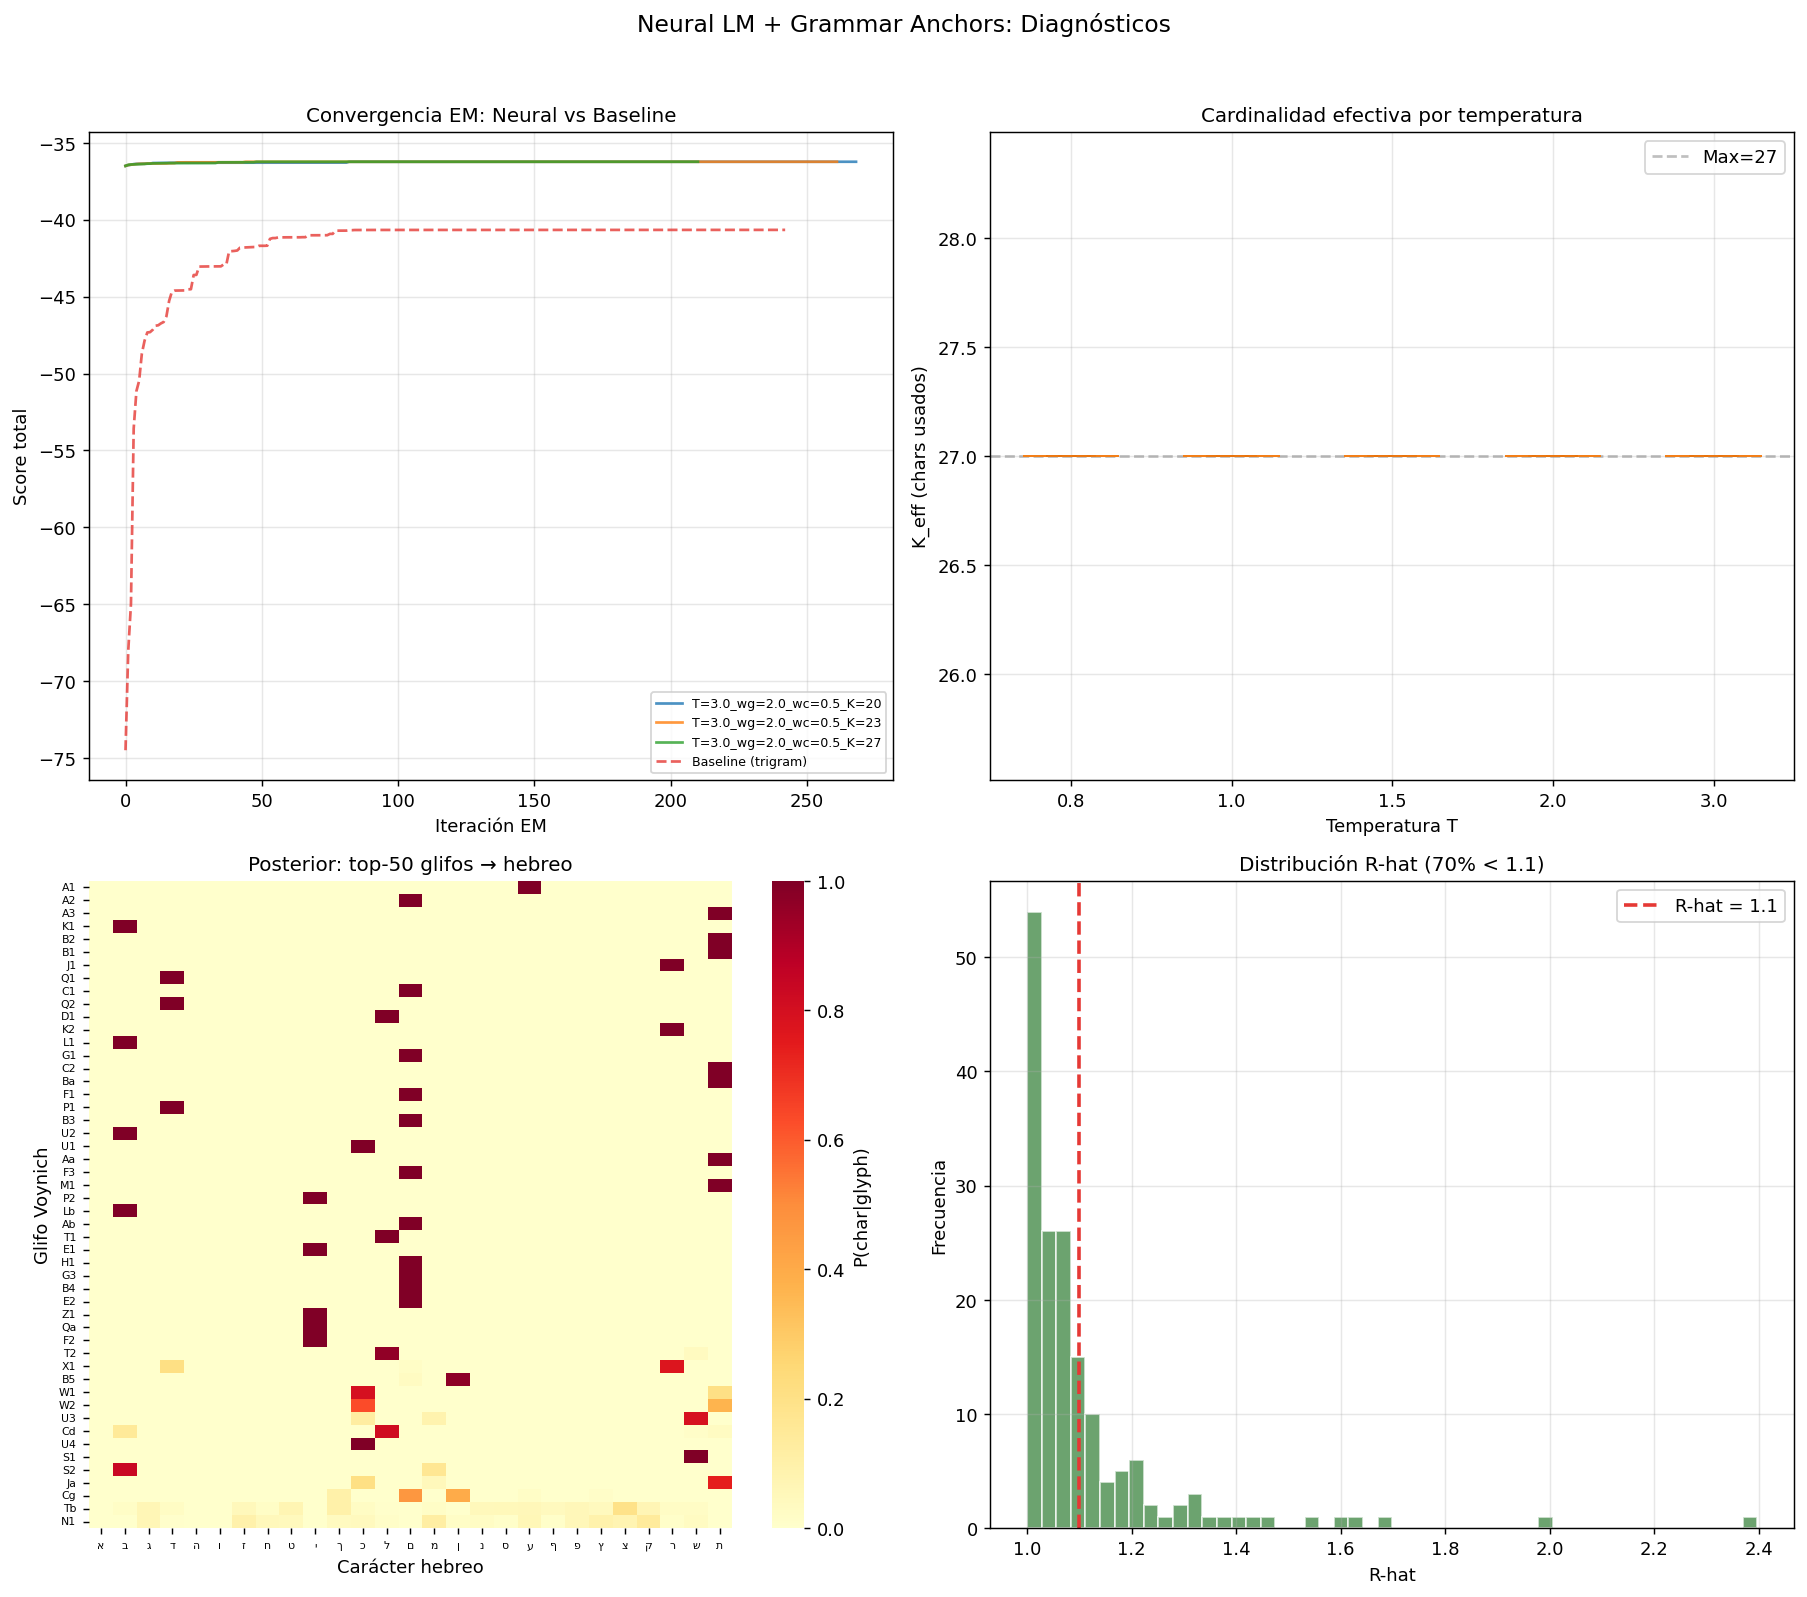

In [13]:
# ── Cell 13: Visualisations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: EM convergence (score vs iteration, neural vs baseline)
ax = axes[0, 0]
for key in EM_RESULTS:
    scores = EM_RESULTS[key]['scores']
    label = key if key != 'baseline_trigram' else 'Baseline (trigram)'
    color = '#E53935' if key == 'baseline_trigram' else None
    ls = '--' if key == 'baseline_trigram' else '-'
    ax.plot(scores, label=label[:30], linestyle=ls, color=color, alpha=0.8)
ax.set_xlabel('EM iteration')
ax.set_ylabel('Total score')
ax.set_title('EM Convergence: Neural vs Baseline')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# Plot 2: Cardinality distribution by temperature (from sweep)
ax = axes[0, 1]
T_groups = defaultdict(list)
for r in sweep_results:
    T_groups[r['T']].append(r['K_eff'])
positions = list(range(len(T_VALUES)))
bp_data = [T_groups[T] for T in T_VALUES]
bp = ax.boxplot(bp_data, positions=positions, widths=0.6, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('#1565C0')
    patch.set_alpha(0.5)
ax.set_xticks(positions)
ax.set_xticklabels([str(T) for T in T_VALUES])
ax.set_xlabel('Temperature T')
ax.set_ylabel('K_eff (chars used)')
ax.set_title('Effective cardinality by temperature')
ax.axhline(len(target_chars_heb), linestyle='--', color='gray', alpha=0.5, label=f'Max={len(target_chars_heb)}')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Mapping heatmap (top-50 glyphs → Hebrew characters)
ax = axes[1, 0]
top50_glyphs = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:50]
heatmap_data = np.zeros((len(top50_glyphs), len(target_chars_heb)))
for i, g in enumerate(top50_glyphs):
    if g in posterior_neural:
        for c, prob in posterior_neural[g].items():
            if c in target_chars_heb:
                j = target_chars_heb.index(c)
                heatmap_data[i, j] = prob

sns.heatmap(heatmap_data, ax=ax, cmap='YlOrRd',
            xticklabels=target_chars_heb, yticklabels=top50_glyphs,
            cbar_kws={'label': 'P(char|glyph)'})
ax.set_xlabel('Hebrew character')
ax.set_ylabel('Voynich glyph')
ax.set_title('Posterior: top-50 glyphs → Hebrew')
ax.tick_params(labelsize=6)

# Plot 4: R-hat distribution
ax = axes[1, 1]
rhat_finite = [v for v in rhat_vals if v < 5.0]
ax.hist(rhat_finite, bins=50, color='#2E7D32', alpha=0.7, edgecolor='white')
ax.axvline(1.1, color='#E53935', linestyle='--', linewidth=2, label='R-hat = 1.1')
ax.set_xlabel('R-hat')
ax.set_ylabel('Frequency')
ax.set_title(f'R-hat Distribution ({pct_converged:.0f}% < 1.1)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Neural LM + Grammar Anchors: Diagnostics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [17]:
# ── Cell 14: Export results ──────────────────────────────────────

# Serialize mapping (convert sets to lists for JSON)
mapping_serializable = {g: c for g, c in mapping_neural.items()}

# Posterior serializable
posterior_serializable = {}
for g, dist in posterior_neural.items():
    posterior_serializable[g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

resultados = {
    'metadata': {
        'notebook': '12_neural_lm.ipynb',
        'model': 'neural_lstm_temperature',
        'language': 'hebrew',
        'description': 'Neural CharLM (LSTM) + grammar anchors + cardinality constraints',
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
        'baseline_ppx': float(baseline_val_ppx),
        'neural_ppx_T1': float(neural_val_ppx),
    },
    'best_config': {
        'temperature': float(T_best),
        'w_lm': 2.0, 'w_pos': 0.5,
        'w_gram': float(w_gram_best),
        'w_card': float(w_card_best),
        'K_max': int(K_max_best),
    },
    'temperature_sweep': [
        {'T': float(r['T']), 'H_mean': round(float(r['H_mean']), 4),
         'PPX': round(float(r['PPX']), 2)}
        for r in temp_results
    ],
    'em_results': {
        key: {
            'T': float(r['T']) if r['T'] is not None else None,
            'final_score': round(float(r['final_score']), 4),
            'K_final': int(r.get('K_final', len(set(r['state'].mapping.values())))),
            'grammar': round(float(r.get('grammar', 0)), 3),
            'iter_converged': int(r.get('iter_converged', len(r['scores']))),
        }
        for key, r in EM_RESULTS.items()
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched)),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'grammar_anchor_pct': round(float(pct_anchor), 3),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'mapping': mapping_serializable,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_neural.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'comparison_table': comparison_rows,
}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

with open('neural_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to neural_resultados.json')
print(f'Keys: {list(resultados.keys())}')

# Quick summary
print(f'\n── Final summary ──')
print(f'Model: Neural LSTM + Grammar Anchors')
print(f'Language: Hebrew')
print(f'Optimal temperature: T={T_best}')
print(f'Cardinality: {K_neural}/{len(target_chars_heb)} chars')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')
print(f'R-hat convergence: {pct_converged:.0f}%')

Resultados exportados a neural_resultados.json
Keys: ['metadata', 'neural_lm', 'best_config', 'temperature_sweep', 'em_results', 'mcmc_results', 'validation_scorecard', 'validation_details', 'scorecard_summary', 'mapping', 'posterior_top', 'rhat', 'comparison_table']

── Resumen final ──
Modelo: Neural LSTM + Grammar Anchors
Lengua: Hebreo
Temperatura óptima: T=3.0
Cardinalidad: 26/27 chars
Scorecard: 4 PASS / 0 MARGINAL / 1 FAIL
R-hat convergencia: 70%
